<a href="https://colab.research.google.com/github/bcramp/ML/blob/main/HW5/Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

HW 5

Title: Assignment Analysis

Name: Brennen Cramp

Date: 10/26/2026

---

# Analysis
---

1. In raw medical environments, missing data would rarely present itself as clean, pre-coded blanks where it would take the form of hidden or implicit missing values, such as non-standard text placeholders (e.g., "?", "Unknown", NaN, 0, or 999). Of the options provided, 0 was the numerical placeholder used in features where 0 is not a possible value (i.e. 'glucose', 'blood_pressure', etc). Now, if these zeros were treated as actual data points, they would falsely skew the feature distributions downward, artificially inflating the variance and pulling down the true mean. This could also lead to dangerous misinterpretations from the model due to misclassifying diabetic patients as healthy due to a missing metric being seen as extremely low. In continuation, this would also mean that these rows should not be outright deleted, but simply imputed to adjust for these missing values. Dropping every row containing an implicit zero would drastically reduce the dataset size, discarding valuable information present in the non-zero columns of those rows and this sample-selection bias would make the model only learn from patients who had perfect records. To account for 0s for certain features ('glucose', 'blood_pressure', 'skin_thickness', 'insulin', and 'bmi') where it could not be possible to have a 0, I updated these values to be 'NaN' to show to my imputer that these are actual missing values. I chose the median strategy rather than the mean since this telemetry would often contain severely-skewed distributions due to outliers. Mean would be highly sensitive to these extremes and using it would artificially inflate the imputed values for typical patients. Finally, for this dataset, no categorical imputations were needed since all features were already 'int64' or 'float64' types (with exception to the target 'outcome' which I had to coerce to an integer type).

2. Hard voting (majority rule) aggregates predictions by counting the discrete class labels predicted by each base estimator. Each model in the ensemble casts one equal vote for a specific class (0 or 1). The class that receives the majority of individual votes is selected as the final prediction. As an example, if the Logistic Regression model predicts 1, SVC model predicts 1, and a Decision Tree model predicts 0, hard voting assigns a final label of 1. On the other hand, soft voting (probability averaging), aggregates predictions by calculating the mean of the predicted class probabilities across all base estimators. Instead of forcing each model to pick a strict label, soft voting allows models to express their degree of certainty. The ensemble sums up the probabilities for each class and selects the class with the highest average probability which allows a highly confident model to override the uncertain predictions of other estimators. When implementing soft voting across heterogeneous models, well-calibrated probability estimates are crucial for a great model. Each algorithm gnerates probabilities based on different mathetmatical functions such as Logistic Regression (LR) optimizing a log-loss function and produces naturally well-calibrated probabilities or a Support Vector Classifier (SVC) producing uncalibrated distance metrics from a decision hyperplane or how a Decision Tree outputs fractions based on its leaf nodes. These could cause issues for calibration. If an algorithm is poorly calibrated, it will output highly overconfident probabilities even when it is wrong. In a soft voting ensemble, an uncalibrated, overconfident model will skew the average probability, completely masking the intricacies of well-calibrated models and rendering the soft voting model unstable or highly inaccurate. This can be seen in the metrics and graph produced from Task 5 where hard voting significantly outperformed soft voting (0.7792 versus 0.7403). This occurs because the uncalibrated probability of an unpruned Decision Tree (which naturally pushes extreme 0 or 1 probability values at its leaves) messed with the soft voting averages, dragging down the balanced predictions of the logisitic and support vector models.

3. In a Bagging classifier, individual base estimators are trained on bootstrapped subsets of the training data and because bootstrapping sample data with replacements, not every training instance will make it into every base estimator's training pool. The role of OOB evaluation is to utilize the neglected samples as an internal, built-in validation set. For every single row in the dataset, the ensemble identifies all base estimators that were not trained on that specific row, aggregates their predictions, and calculates an overall validation metric as the OOB Score. OOB serves as an efficient alternative to cross-validation because traditional k-fold cross-validation is very expensive, computationally. The splitting that is required for the dataset into k-partitions and completely re-training the entire ensemble model k-times is a heavy load to handle. For massive ensembles, this multiplies the training time by a factor of k. OOB evaluation requires zero additional training cycles since the data splitting happens in-step as a side effect of the bootstrap sampling. Also, the ensemble evaluates itself dynamically during a single training run where it provides a reliable, unbiased estimation of how well the model will genrealize to unseen test data (such as the held-out test split) without sacrificing any data to a separate static validation set or executing unneeded training loops.

4. Introducing random feature subsetting in Random Forests differs from standard Bagging because in standard bagging, when growing decision trees, each tree is built using a bootstrapped subset of observations, but the algorithm considers all available features at every split point. If a dataset has a single dominant predictive feature, almost every single tree in the bagging ensemble will select that same feature for its top-level splits. This creates an ensemble of structurally similar, highly correlated trees. A Random Forest introduces an additional layer of randomness with the random feature subsetting in that when splitting a node during tree construction, the algorithm is restricted from looking at the entire feature pool. Instead, it forces each split to choose from a randomly sampled subset of features. The feature importance chart produced during Task 7 shows why this constraint is necessary since the plot demonstrates that 'glucose' is the most dominant predictive metric by a massive margin (nearly 25% of the total Mean Decrease in Impurity), followed by 'bmi'. Without feature subsetting, almost every individual tree in a standard Bagging pool would first split on 'glucose' or 'bmi'. This would cause the trees to look virtually identical, heavily limiting the diversity of the ensemble. By forcing a subset of trees to ignore 'glucose' and 'bmi' at any given node split, Random Forests decorrelate the individual trees which forces the models to discover hidden patterns in less dominant features like 'age', 'diabetes_pedigree_function', and 'blood_pressure'. For the impact of feature diversity on variance and generalization, while forcing individual trees to split on weaker features that might make those individual trees slightly less accurate (introducing small bias), averaging their predictions across the ensemble significantly reduces overall model variance. In terms of generalization, the Random Forest (Task 7) successfully converted this structural diversity into an increased test accuracy of 0.7922 (with a balanced F1-score of 0.76). By compelling a diverse range of trees to evaluate different subsets of clinical attributes, the ensemble became more robust to noise and less vulnerable to overfitting on dominant features.

5. AdaBoost operates sequentially, unlike parallel ensembles that train models independently. It starts by assigning an equal sample weight to every patient record in the training dataset where the first weak learner, a single-split decision stump, is trained on this uniform distribution and AdaBoost computes the total weighted error of that decision stump. Instances where the stump misclassifies are assigned a higher sample weight, while correctly classified instances have their weights decreased, creating an adaptive nature to the model classifier. When the next decision stump is trained, it is forced to focus heavily on the previously misclassified patients. This process repeats for every estimator, with each tree attempting to correct the exact flaws of its predecessors. This results with the final prediction that is calculated as a weighted vote of all stumps, where more accurate stumps carry more voting power. The results shown for training accuracy (0.7899) versus the held-out test accuracy (0.7662) metrics in Task 8 perfecty describes AdaBoost's generalization properties. AdaBoost did not exhibit any significant signs of overfitting because in typical overfitting scenarios, a near-perfect training accuracy (close to 1) alongside a severely degraded test accuracy would be the massive indicator. In this case, the difference between training and testing is very small with roughly 2.4% between the values. This minimal generalization gap proves that by utilizing highly restricted decision stumps (by setting the max_depth to 1) combined with a conservative learning rate of 0.1, the model successfully resisted the trend to memorize the training data. Instead, it slowly and smoothly constructed a stable decision boundary. However, if the boosting model was to show signs of overfitting, hyperparameters such as the learning rate and number of estimators should be adjusted to mitigate this. Reducing the learning rate forces the alogrithm to scale down the impact of each sequential tree's weight adjustments which would require the model to take smaller and safer steps towards the optimal solution. Additionally, depending on the number of estimators, if an ensemble runs for too many iterations, it eventually begins to force trees to correct for random noise/outliers in the training set. Decreasing the number of estimators will cap the total number of sequential trees, breaking this cycle earlier.

# **Ensemble Voting Classifier Comparison Bar Chart (Task 5):**

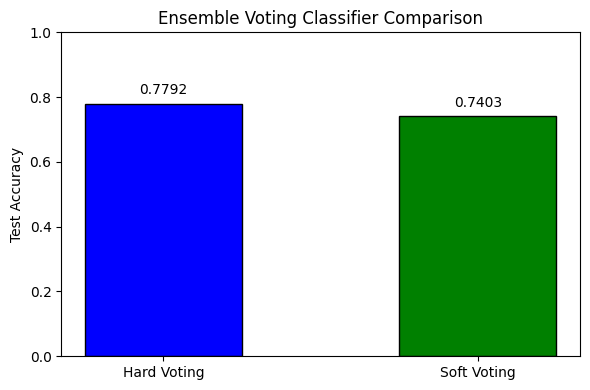

# **Bagging Classifier: OOB Score vs. Test Accuracy Bar Chart (Task 6):**

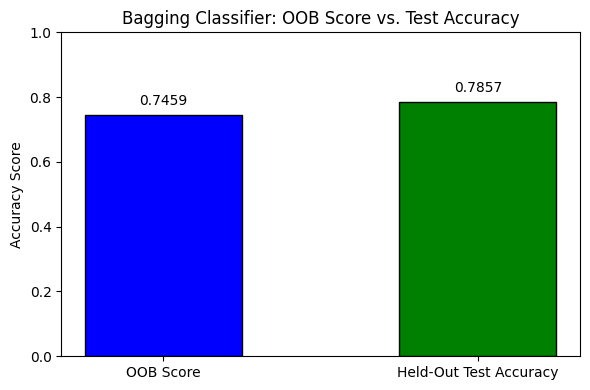

# **Random Forest Feature Importance Analysis Bar Chart (Task 7):**

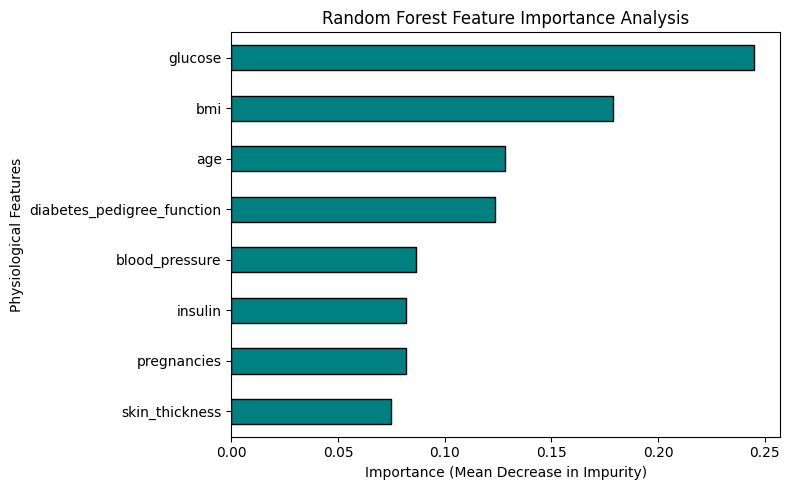

# **AdaBoost: Training vs. Test Performance Bar Chart (Task 8):**

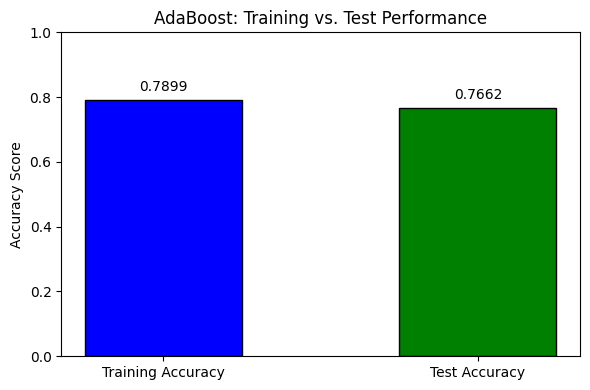